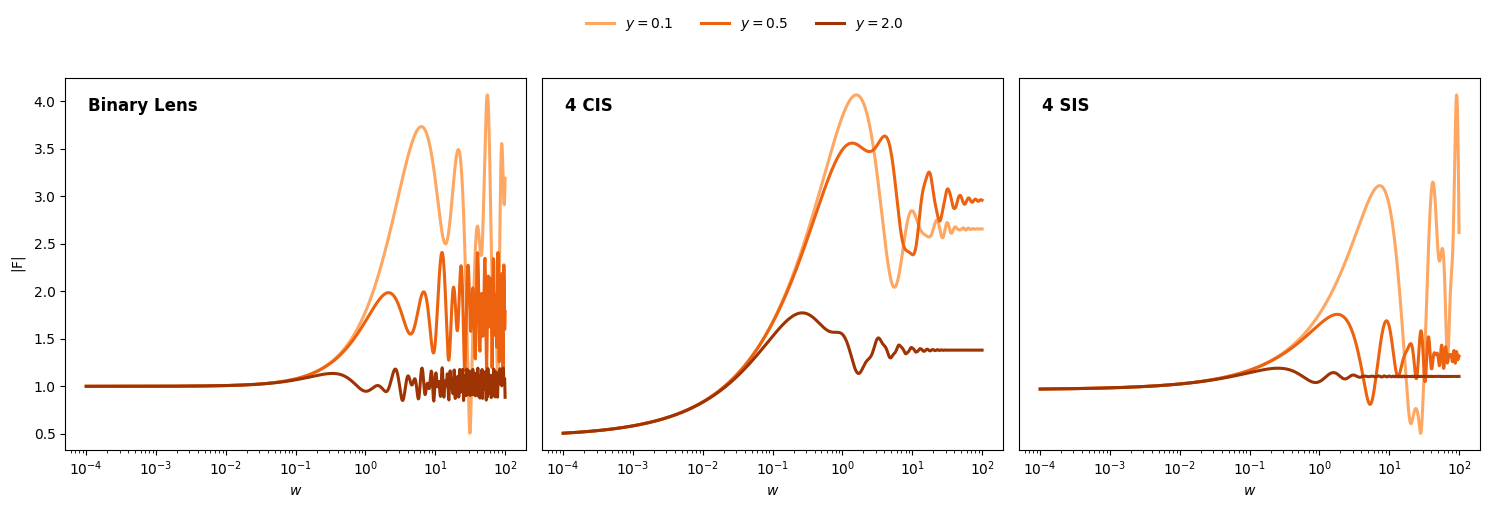

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens import solver2d
from gwlens.tools import plotting

#plotting.apply_figure_style()
n =4
norm_cis = 1/n
rc = 0.05

# Colormaps
glow_cmap = plt.get_cmap("Blues")
gwlens_cmap = plt.get_cmap("Oranges")

def distribute_centers(n, R=1.0, seed=0):
    """Identical recipe to glow_worker_msis.distribute_centers (own RNG, centre of mass at 0)."""
    rng = np.random.RandomState(seed)
    Rs = R * np.sqrt(rng.random_sample(n))
    ths = 2 * np.pi * rng.random_sample(n)
    x1, x2 = Rs * np.cos(ths), Rs * np.sin(ths)
    return x1 - x1.mean(), x2 - x2.mean()


def multi_sis(n, seed, R):
    xc1, xc2 = distribute_centers(n, R, seed)
    lens = None
    for a, b in zip(xc1, xc2):
        piece = solver2d.sis(1.0 / n, (a, b))                 # psi0 = 1/n each
        lens = piece if lens is None else lens + piece
    return lens


lens_binary = solver2d.point_mass(0.5,(-0.5,0)) + solver2d.point_mass(0.5,(0.5,0.0))
lens_cis_four = solver2d.cis(norm_cis,rc,(-1,-1)) + solver2d.cis(norm_cis,rc,(-1,1)) +solver2d.cis(norm_cis,rc,(1,-1)) + solver2d.cis(norm_cis,rc,(1,1))
lens_4_sis = multi_sis(4,1234,1.0)
# Select lens models to plot
lens = [lens_binary, lens_cis_four,lens_4_sis]

# Names displayed inside each subplot
lens_names = ["Binary Lens", "4 CIS","4 SIS" ]

ws = np.logspace(-4,2,1000)
y_values = [0.1,0.5,2.0]

# Colors corresponding to each y value
colors = np.linspace(0.4, 0.9, len(y_values))


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#lens_names = [lens_binary,  lens_cis_four]

for ax, lens_model, lens_name in zip(axes,lens, lens_names):

     # Plot amplification for each y value
    for i, y_i in enumerate(y_values):
        
        F = solver2d.amplification_many(ws,(y_i,0.0),lens_model, n_workers=8 )

        ax.semilogx(ws,np.abs(F),label=fr"$y = {y_i}$", color=gwlens_cmap(colors[i]),linewidth=2.2  )

    # Add lens name inside the subplot
    ax.text(0.05, 0.95, lens_name, transform=ax.transAxes,  fontsize=12,  fontweight="bold", ha="left", va="top" )

    # Axis labels
    ax.set_xlabel(r"$w$")
    ax.set_ylabel(r"$|\mathrm{F}|$")

# Remove repeated y-axis labels from second and third subplots
for ax in axes[1:]:
    ax.set_ylabel("")
    ax.tick_params(axis="y",left=False, labelleft=False  )

# Remove repeated y-axis labels from second and third subplots
for ax in axes[1:]:
    ax.set_ylabel("")
    ax.tick_params( axis="y",left=False,  labelleft=False )

# Create one shared legend using the first subplot's line labels
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(handles,labels, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=len(y_values), frameon=False)

# Adjust layout to leave room for the legend
fig.tight_layout(rect=[0, 0, 1, 0.90])

# Display the figure
plt.show()